In [3]:
%matplotlib inline

import itertools
import json
import random
import string

import geopandas as gpd
import matplotlib.pyplot as plt
import shapely.geometry as geom

from weavingspace import TileUnit, Tiling, tiling_utils
from weavingspace._regular_tilings import Symbols

num = int | float # convenience for cleaner typing

TILE_IDS = [
  *string.ascii_lowercase,
  *["".join(x) for x in itertools.product(
    string.ascii_lowercase, string.ascii_lowercase)]
]
R2 = 2 ** 0.5
R3 = 3 ** 0.5

# # read tile specs from supplied JSON
# # note that there are definitely duplicates
# with open("tiles.json") as file:
#   Symbols1 = json.load(file)
# with open("tiles-2.json") as file:
#   Symbols2 = json.load(file)
# Symbols = Symbols1 | Symbols2

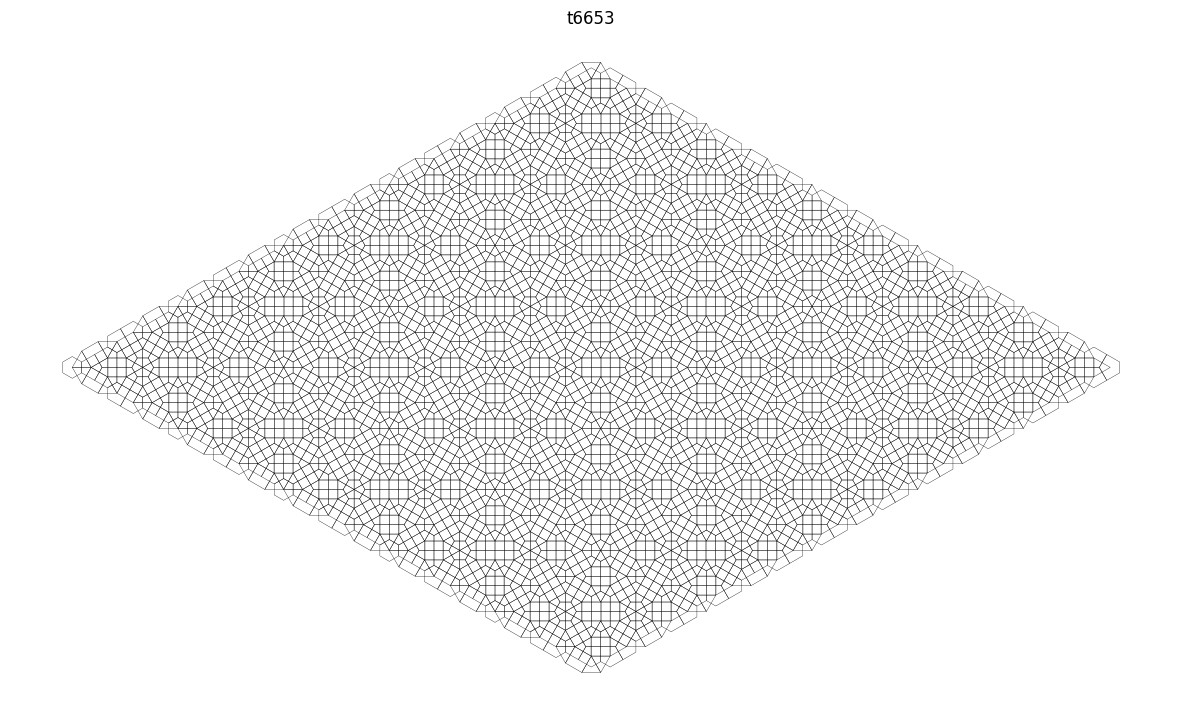

In [13]:
code = random.choice(list(Symbols.keys()))

t1 = TileUnit(tiling_type = "regular", code = code, spacing = 400)
#  \
#   .transform_rotate(-15)
t2 = TileUnit(tiling_type = "regular", code = code, spacing = 400, dual = True)
#  \
#   .transform_rotate(-15)
vs = t1.get_vectors()

fig = plt.figure(figsize = (15, 15))
ax = fig.add_subplot(111)
(t1.get_local_patch(r = 2, include_0 = True)
  .plot(ax = ax, lw = 0.25, ec = "k", fc = "#00000000")
)
(t2.get_local_patch(r = 2, include_0 = True)
  # .translate(*(2 * x for x in vs[0]))
  .plot(ax = ax, lw = 0.25, ec = "k", fc = "#00000000")
)
ax.set_title(code)
ax.set_axis_off()